<a href="https://colab.research.google.com/github/Abidau/MachineLearning/blob/main/TG13_244107020212_NaufalAbidAurizky.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Praktikum 1
## 1. Kode Dasar (Konfigurasi Awal)

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Dataset XOR
X = np.array([[0,0],[0,1],[1,0],[1,1]])
y = np.array([[0],[1],[1],[0]])

# Parameter
input_size = 2
hidden_size = 2
output_size = 1
lr = 0.1

# Inisialisasi bobot (seed agar hasil bisa diulang)
np.random.seed(0)
W1 = np.random.randn(input_size, hidden_size)
b1 = np.zeros((1, hidden_size))
W2 = np.random.randn(hidden_size, output_size)
b2 = np.zeros((1, output_size))

# Fungsi aktivasi
def sigmoid(x):
    return 1 / (1 + np.exp(-x))

def sigmoid_derivative(x):
    return x * (1 - x)   # x di sini = output sigmoid

# Training
loss_awal = []
for epoch in range(10000):
    # Forward pass
    z1 = np.dot(X, W1) + b1
    a1 = sigmoid(z1)
    z2 = np.dot(a1, W2) + b2
    a2 = sigmoid(z2)

    # Hitung error
    error = y - a2

    # Backpropagation
    d_a2 = error * sigmoid_derivative(a2)
    d_W2 = np.dot(a1.T, d_a2)
    d_b2 = np.sum(d_a2, axis=0, keepdims=True)

    d_a1 = np.dot(d_a2, W2.T) * sigmoid_derivative(a1)
    d_W1 = np.dot(X.T, d_a1)
    d_b1 = np.sum(d_a1, axis=0, keepdims=True)

    # Update bobot
    W1 += lr * d_W1
    b1 += lr * d_b1
    W2 += lr * d_W2
    b2 += lr * d_b2

    loss = np.mean(np.square(error))
    loss_awal.append(loss)
    if epoch % 1000 == 0:
        print(f"Epoch {epoch}, Loss: {loss}")

# Output akhir
print("Prediksi:")
print(a2)

Epoch 0, Loss: 0.2696367200181884
Epoch 1000, Loss: 0.1750060710642713
Epoch 2000, Loss: 0.14613094454674402
Epoch 3000, Loss: 0.1368350751574775
Epoch 4000, Loss: 0.13288176632884824
Epoch 5000, Loss: 0.13080399496399958
Epoch 6000, Loss: 0.12955145571861038
Epoch 7000, Loss: 0.12872371423208248
Epoch 8000, Loss: 0.12814004233797888
Epoch 9000, Loss: 0.12770828200389944
Prediksi:
[[0.03839952]
 [0.49858597]
 [0.95203168]
 [0.50429904]]


## 2. Fungsi Training yang Bisa Dikonfigurasi

In [ ]:
def relu(x):
    return np.maximum(0, x)

def relu_derivative(z):          # z = pre-aktivasi
    return (z > 0).astype(float)


def train(hidden_size=2, activation="sigmoid", lr=0.1, epochs=10000, seed=0):
    rng = np.random.default_rng(seed)
    W1 = rng.standard_normal((2, hidden_size))
    b1 = np.zeros((1, hidden_size))
    W2 = rng.standard_normal((hidden_size, 1))
    b2 = np.zeros((1, 1))

    losses = []
    for epoch in range(epochs):
        # Forward pass
        z1 = X @ W1 + b1
        a1 = sigmoid(z1) if activation == "sigmoid" else relu(z1)
        z2 = a1 @ W2 + b2
        a2 = sigmoid(z2)

        # Error & loss
        error = y - a2
        losses.append(np.mean(np.square(error)))

        # Backpropagation
        d_a2 = error * sigmoid_derivative(a2)
        d_W2 = a1.T @ d_a2
        d_b2 = np.sum(d_a2, axis=0, keepdims=True)

        if activation == "sigmoid":
            d_a1 = (d_a2 @ W2.T) * sigmoid_derivative(a1)
        else:
            d_a1 = (d_a2 @ W2.T) * relu_derivative(z1)
        d_W1 = X.T @ d_a1
        d_b1 = np.sum(d_a1, axis=0, keepdims=True)

        # Update bobot
        W1 += lr * d_W1; b1 += lr * d_b1
        W2 += lr * d_W2; b2 += lr * d_b2

    return losses, a2

## 3. Tugas 1a Hidden Layer = 3 Neuron

In [ ]:
losses_h2, pred_h2 = train(hidden_size=2, activation="sigmoid", seed=0)
losses_h3, pred_h3 = train(hidden_size=3, activation="sigmoid", seed=0)

print("Hidden 2 (awal) = loss akhir:", round(losses_h2[-1], 6))
print("Prediksi:", np.round(pred_h2.ravel(), 3))
print()
print("Hidden 3        = loss akhir:", round(losses_h3[-1], 6))
print("Prediksi:", np.round(pred_h3.ravel(), 3))

Hidden 2 (awal) = loss akhir: 0.014471
Prediksi: [0.123 0.88  0.871 0.107]

Hidden 3        = loss akhir: 0.002985
Prediksi: [0.03  0.944 0.946 0.071]


## 4. Tugas 1b Perbandingan Loss dengan Konfigurasi Awal

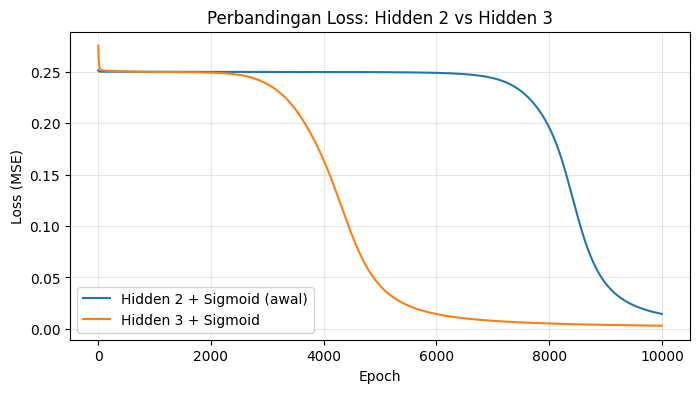

   Epoch     Hidden 2     Hidden 3
       0     0.251400     0.275391
    1000     0.250029     0.249929
    3000     0.249944     0.238094
    5000     0.249689     0.041952
    9999     0.014471     0.002985


In [ ]:
plt.figure(figsize=(8,4))
plt.plot(losses_h2, label="Hidden 2 + Sigmoid (awal)")
plt.plot(losses_h3, label="Hidden 3 + Sigmoid")
plt.xlabel("Epoch"); plt.ylabel("Loss (MSE)")
plt.title("Perbandingan Loss: Hidden 2 vs Hidden 3")
plt.legend(); plt.grid(alpha=0.3)
plt.show()

print(f"{'Epoch':>8s} {'Hidden 2':>12s} {'Hidden 3':>12s}")
for e in [0, 1000, 3000, 5000, 9999]:
    print(f"{e:8d} {losses_h2[e]:12.6f} {losses_h3[e]:12.6f}")

## 5. Tugas 1c Fungsi Aktivasi ReLU

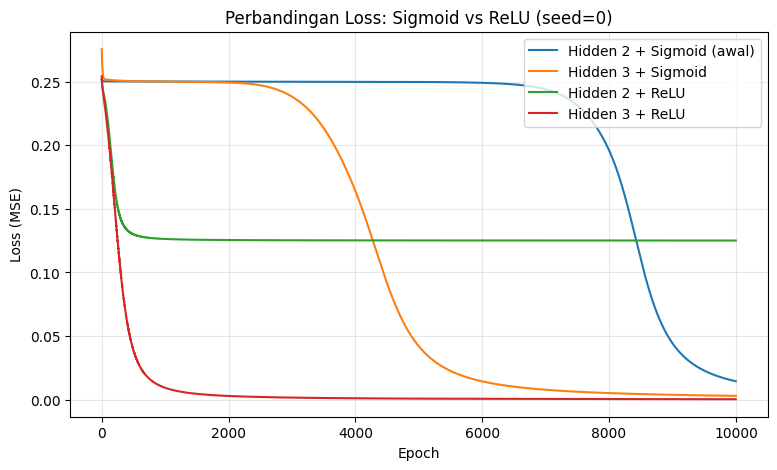

Konfigurasi                     Loss@0  Loss@1000  Loss@5000  Loss akhir
Hidden 2 + Sigmoid (awal)      0.25140    0.25003    0.24969    0.014471
   prediksi: [0.123 0.88  0.871 0.107]
Hidden 3 + Sigmoid             0.27539    0.24993    0.04195    0.002985
   prediksi: [0.03  0.944 0.946 0.071]
Hidden 2 + ReLU                0.25190    0.12632    0.12512    0.125054
   prediksi: [0.5   0.99  0.5   0.011]
Hidden 3 + ReLU                0.25418    0.00933    0.00081    0.000345
   prediksi: [0.029 0.986 0.986 0.012]


In [ ]:
configs = [
    ("Hidden 2 + Sigmoid (awal)", 2, "sigmoid"),
    ("Hidden 3 + Sigmoid",        3, "sigmoid"),
    ("Hidden 2 + ReLU",           2, "relu"),
    ("Hidden 3 + ReLU",           3, "relu"),
]

results = {}
for name, h, act in configs:
    losses, pred = train(hidden_size=h, activation=act, seed=0)
    results[name] = (losses, pred)

plt.figure(figsize=(9,5))
for name, (losses, _) in results.items():
    plt.plot(losses, label=name)
plt.xlabel("Epoch"); plt.ylabel("Loss (MSE)")
plt.title("Perbandingan Loss: Sigmoid vs ReLU (seed=0)")
plt.legend(); plt.grid(alpha=0.3)
plt.show()

print(f"{'Konfigurasi':28s} {'Loss@0':>9s} {'Loss@1000':>10s} {'Loss@5000':>10s} {'Loss akhir':>11s}")
for name, (losses, pred) in results.items():
    print(f"{name:28s} {losses[0]:9.5f} {losses[1000]:10.5f} {losses[5000]:10.5f} {losses[-1]:11.6f}")
    print("   prediksi:", np.round(pred.ravel(), 3))

# Praktikum 2

In [5]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
import tensorflow as tf

# Load dataset
iris = load_iris()
X = iris.data
y = iris.target.reshape(-1, 1)

# One-hot encoding
encoder = OneHotEncoder(sparse_output=False)  # ganti ke sparse=False jika sklearn versi lama
y = encoder.fit_transform(y)

# Split data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2)

# ============================================================
# PRAKTIKUM 2: Konfigurasi awal (10-8, ReLU)
# ============================================================
# Bangun model
model = tf.keras.Sequential([
    tf.keras.layers.Dense(10, activation='relu', input_shape=(4,)),
    tf.keras.layers.Dense(8, activation='relu'),
    tf.keras.layers.Dense(3, activation='softmax')
])

# Kompilasi
model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

# Latih model
model.fit(X_train, y_train, epochs=50, batch_size=8)

# Evaluasi
loss, acc = model.evaluate(X_test, y_test)
print(f"Akurasi: {acc}")

loss_awal, acc_awal = loss, acc


Epoch 1/50


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


15/15 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.0750 - loss: 1.2432    
Epoch 2/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.0833 - loss: 1.1987     
Epoch 3/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.0833 - loss: 1.1691 
Epoch 4/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.0750 - loss: 1.1468     
Epoch 5/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.1000 - loss: 1.1103     
Epoch 6/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.1417 - loss: 1.0825 
Epoch 7/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.4000 - loss: 1.0805 
Epoch 8/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.4667 - loss: 1.0482 
Epoch 9/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.4167 - loss: 1.0033 
Epoch 10/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.3833 - loss: 0.9708 
Epoch 11/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.3833 - loss: 0.9435 
Epoch 12/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accura

## Tugas 2

Membandingkan Jumlah Neuron Hidden Layer

In [8]:
konfigurasi = [(4, 3), (16, 8), (32, 16), (64, 32)]
hasil_tugas2 = [("Awal (10-8)", loss_awal, acc_awal)]

for n1, n2 in konfigurasi:
    model2 = tf.keras.Sequential([
        tf.keras.layers.Dense(n1, activation='relu', input_shape=(4,)),
        tf.keras.layers.Dense(n2, activation='relu'),
        tf.keras.layers.Dense(3, activation='softmax')
    ])
    model2.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
    model2.fit(X_train, y_train, epochs=50, batch_size=8, verbose=0)
    l, a = model2.evaluate(X_test, y_test, verbose=0)
    hasil_tugas2.append((f"({n1}-{n2})", l, a))

print(f"{'Konfigurasi':<15}{'Loss':<12}{'Akurasi':<10}{'Selisih vs Awal'}")
for nama, l, a in hasil_tugas2:
    print(f"{nama:<15}{l:<12.4f}{a:<10.4f}{a - acc_awal:+.4f}")

Konfigurasi    Loss        Akurasi   Selisih vs Awal
Awal (10-8)    0.3116      1.0000    +0.0000
(4-3)          0.5312      0.5333    -0.4667
(16-8)         0.2042      0.9667    -0.0333
(32-16)        0.1194      1.0000    +0.0000
(64-32)        0.0515      1.0000    +0.0000


## Tugas 3

Membandingkan Sigmoid vs ReLU

In [9]:
hasil_tugas3 = []
for aktivasi in ['sigmoid', 'relu']:
    model3 = tf.keras.Sequential([
        tf.keras.layers.Dense(10, activation=aktivasi, input_shape=(4,)),
        tf.keras.layers.Dense(8, activation=aktivasi),
        tf.keras.layers.Dense(3, activation='softmax')
    ])
    model3.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
    hist = model3.fit(X_train, y_train, epochs=50, batch_size=8, verbose=0)
    l, a = model3.evaluate(X_test, y_test, verbose=0)
    hasil_tugas3.append((aktivasi, hist.history['loss'][-1], hist.history['accuracy'][-1], l, a))

print(f"{'Aktivasi':<10}{'Train Loss':<13}{'Train Acc':<12}{'Test Loss':<12}{'Test Acc'}")
for akt, tl, ta, l, a in hasil_tugas3:
    print(f"{akt:<10}{tl:<13.4f}{ta:<12.4f}{l:<12.4f}{a:.4f}")

Aktivasi  Train Loss   Train Acc   Test Loss   Test Acc
sigmoid   0.8360       0.6833      0.8472      0.6000
relu      0.1758       0.9750      0.1490      0.9667


# Praktikum 3

In [10]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import tensorflow as tf

# Contoh dataset (buat dummy data)
data = pd.DataFrame({
    'luas': [50, 60, 70, 80, 90],
    'harga': [500, 600, 700, 800, 900]
})

X = data[['luas']]
y = data[['harga']]

# Normalisasi
scaler = StandardScaler()
X = scaler.fit_transform(X)
y = scaler.fit_transform(y)

# Split data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2)

# Model
model = tf.keras.Sequential([
    tf.keras.layers.Dense(10, activation='relu', input_shape=(1,)),
    tf.keras.layers.Dense(1)
])

model.compile(optimizer='adam', loss='mse')
model.fit(X_train, y_train, epochs=100)

# Evaluasi
print("Prediksi:", model.predict(X_test))

Epoch 1/100


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 673ms/step - loss: 1.6118
Epoch 2/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step - loss: 1.5979
Epoch 3/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 64ms/step - loss: 1.5841
Epoch 4/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step - loss: 1.5703
Epoch 5/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - loss: 1.5565
Epoch 6/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - loss: 1.5428
Epoch 7/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step - loss: 1.5292
Epoch 8/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - loss: 1.5156
Epoch 9/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step - loss: 1.5021
Epoch 10/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step - loss: 1.4886
Epoch 11/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step - loss: 1.4751
Epoch 12/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step - loss: 1.4617
Epoch 13/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step - loss: 1.4484
Epoch 14/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step - loss: 1.4351
Epoch 15/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step - loss: 1.4219
Epoch 16/100
1/1 ━━━━━━━━━━━━━

## Tugas 4

Mengubah Learning rate dan Membandingkan hasil loss

Learning Rate  Loss Awal     Loss Akhir (Train)    Loss Test
0.0001         1.0218        0.925615              0.000002
0.001          1.8731        0.843061              0.004540
0.01           1.2028        0.008948              0.036327
0.1            0.3248        0.000002              0.000252
1.0            2.4061        0.000069              0.000004


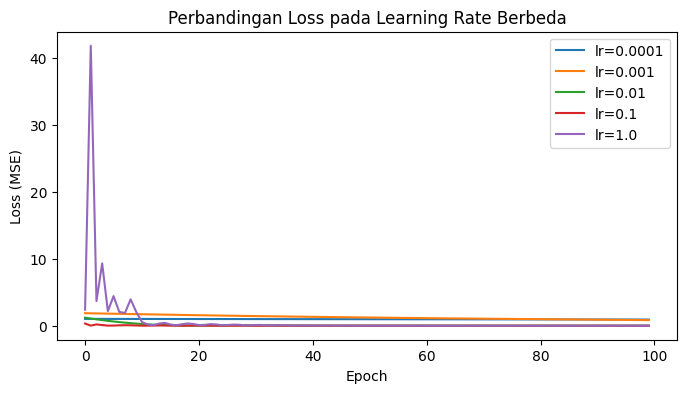

In [13]:
import matplotlib.pyplot as plt
from tensorflow.keras.optimizers import Adam

learning_rates = [0.0001, 0.001, 0.01, 0.1, 1.0]
hasil_tugas4 = []
riwayat_lr = {}

for lr in learning_rates:
    model_lr = tf.keras.Sequential([
        tf.keras.layers.Dense(10, activation='relu', input_shape=(1,)),
        tf.keras.layers.Dense(1)
    ])
    model_lr.compile(optimizer=Adam(learning_rate=lr), loss='mse')
    hist = model_lr.fit(X_train, y_train, epochs=100, verbose=0)
    test_loss = model_lr.evaluate(X_test, y_test, verbose=0)
    riwayat_lr[lr] = hist.history['loss']
    hasil_tugas4.append((lr, hist.history['loss'][0], hist.history['loss'][-1], test_loss))

print(f"{'Learning Rate':<15}{'Loss Awal':<14}{'Loss Akhir (Train)':<22}{'Loss Test'}")
for lr, l0, lf, lt in hasil_tugas4:
    print(f"{lr:<15}{l0:<14.4f}{lf:<22.6f}{lt:.6f}")

# Grafik perbandingan loss
plt.figure(figsize=(8, 4))
for lr, losses in riwayat_lr.items():
    plt.plot(losses, label=f'lr={lr}')
plt.xlabel('Epoch')
plt.ylabel('Loss (MSE)')
plt.title('Perbandingan Loss pada Learning Rate Berbeda')
plt.legend()
plt.show()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


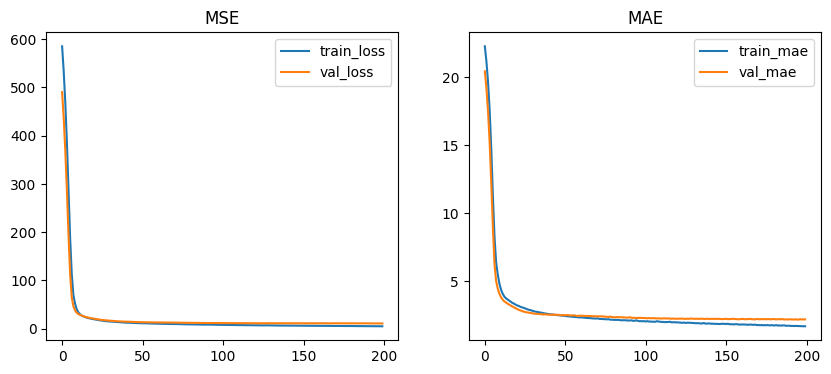

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step
RMSE: 3.3221937188166315


In [14]:
# MLP regresi (Keras)
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.optimizers import Adam

# 1. Load
# (load_boston sudah dihapus di sklearn >= 1.2, maka diberi cadangan lewat fetch_openml)
try:
    from sklearn.datasets import load_boston
    data = load_boston()
    X = data.data; y = data.target
except Exception:
    from sklearn.datasets import fetch_openml
    boston = fetch_openml(name="boston", version=1, as_frame=True)
    X = boston.data.astype(float).values
    y = boston.target.astype(float).values

# 2. Preprocess
scaler = StandardScaler(); Xs = scaler.fit_transform(X)
X_train, X_val, y_train, y_val = train_test_split(Xs, y, test_size=0.2, random_state=42)

# 3. Build model
model = Sequential([
    Dense(64, activation='relu', input_shape=(X_train.shape[1],)),
    Dense(32, activation='relu'),
    Dense(1)
])
model.compile(optimizer=Adam(1e-3), loss='mse', metrics=['mae'])

# 4. Train
h = model.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=200, batch_size=32, verbose=0)

# 5. Plot
plt.figure(figsize=(10,4))
plt.subplot(1,2,1); plt.plot(h.history['loss'], label='train_loss'); plt.plot(h.history['val_loss'], label='val_loss'); plt.legend(); plt.title('MSE')
plt.subplot(1,2,2); plt.plot(h.history['mae'], label='train_mae'); plt.plot(h.history['val_mae'], label='val_mae'); plt.legend(); plt.title('MAE')
plt.show()

from sklearn.metrics import mean_squared_error
pred = model.predict(X_val)
print('RMSE:', np.sqrt(mean_squared_error(y_val, pred)))

# Tugas Praktikum

In [15]:
import tensorflow as tf
from tensorflow.keras.datasets import mnist
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten
from tensorflow.keras.utils import to_categorical
import time

# 1. Load dataset MNIST
(X_train, y_train), (X_test, y_test) = mnist.load_data()

# Normalisasi data (0-255 → 0-1)
X_train = X_train / 255.0
X_test = X_test / 255.0

# One-hot encoding label
y_train = to_categorical(y_train, 10)
y_test = to_categorical(y_test, 10)

# 2. Bangun model JST
model = Sequential([
    # Ubah gambar 28x28 menjadi vektor
    Flatten(input_shape=(28, 28)),
    # Hidden layer 1
    Dense(128, activation='relu'),
    # Hidden layer 2
    Dense(64, activation='relu'),
    # Output layer (10 kelas)
    Dense(10, activation='softmax')
])

# 3. Kompilasi model
model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

# 4. Latih model
start = time.time()
model.fit(X_train, y_train, epochs=10, batch_size=128, validation_split=0.1)
waktu_awal = time.time() - start

# 5. Evaluasi model
loss, acc = model.evaluate(X_test, y_test)
print(f"Akurasi pada data uji: {acc:.4f}")
print(f"Waktu pelatihan: {waktu_awal:.2f} detik")

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - accuracy: 0.9002 - loss: 0.3611 - val_accuracy: 0.9568 - val_loss: 0.1548
Epoch 2/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.9552 - loss: 0.1508 - val_accuracy: 0.9687 - val_loss: 0.1114
Epoch 3/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9680 - loss: 0.1052 - val_accuracy: 0.9745 - val_loss: 0.0898
Epoch 4/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9748 - loss: 0.0810 - val_accuracy: 0.9737 - val_loss: 0.0886
Epoch 5/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.9812 - loss: 0.0615 - val_accuracy: 0.9780 - val_loss: 0.0788
Epoch 6/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.9848 - loss: 0.0507 - val_accuracy: 0.9760 - val_loss: 0.0770
Epoch 7/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.9881 - loss: 0.0394 - val_accuracy: 0.9793 - val_loss: 0.0785
Epoch 8/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9899 - loss: 0.0333 - val_accuracy: 0.

## Mencoba beberapa parameter lain

In [16]:
def eksperimen(nama, hidden, aktivasi='relu', epochs=10):
    layers = [Flatten(input_shape=(28, 28))]
    for n in hidden:
        layers.append(Dense(n, activation=aktivasi))
    layers.append(Dense(10, activation='softmax'))
    m = Sequential(layers)
    m.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

    t0 = time.time()
    m.fit(X_train, y_train, epochs=epochs, batch_size=128, verbose=0)
    waktu = time.time() - t0

    l, a = m.evaluate(X_test, y_test, verbose=0)
    return (nama, l, a, waktu, m.count_params())

hasil = [("Awal (128-64, ReLU)", loss, acc, waktu_awal, model.count_params())]

# Ubah jumlah neuron hidden layer (256 dan 128)
hasil.append(eksperimen("Neuron 256-128, ReLU", [256, 128], 'relu'))

# Tambah satu hidden layer lagi
hasil.append(eksperimen("3 Hidden (128-64-32), ReLU", [128, 64, 32], 'relu'))
hasil.append(eksperimen("3 Hidden (256-128-64), ReLU", [256, 128, 64], 'relu'))

# Sigmoid vs ReLU
hasil.append(eksperimen("Sigmoid 128-64", [128, 64], 'sigmoid'))
hasil.append(eksperimen("ReLU 128-64", [128, 64], 'relu'))

# Tabel perbandingan
print("PERBANDINGAN AKURASI DAN WAKTU PELATIHAN")
print(f"{'Konfigurasi':<30}{'Loss':<10}{'Akurasi':<10}{'Waktu (detik)':<16}{'Jumlah Parameter'}")
for nama, l, a, w, p in hasil:
    print(f"{nama:<30}{l:<10.4f}{a:<10.4f}{w:<16.2f}{p}")

PERBANDINGAN AKURASI DAN WAKTU PELATIHAN
Konfigurasi                   Loss      Akurasi   Waktu (detik)   Jumlah Parameter
Awal (128-64, ReLU)           0.0758    0.9791    29.95           109386
Neuron 256-128, ReLU          0.0740    0.9799    48.06           235146
3 Hidden (128-64-32), ReLU    0.0909    0.9734    26.91           111146
3 Hidden (256-128-64), ReLU   0.0816    0.9791    50.55           242762
Sigmoid 128-64                0.0827    0.9744    28.07           109386
ReLU 128-64                   0.0867    0.9774    26.33           109386
